# Homework 6: Linear Regression Modleing and Diagnostics
Build a predictive model for life expectancy using scikit-learn and perform a diagnostic audit to ensure the model’s coefficients are stable and mathematically sound.

## Task 1: Baseline Modeling
Load the WHO Life Expectancy Dataset, remove non-numeric columns (Country, Year), Convert Status column to  numeric, handle missing values.
- Use StandardScaler from sklearn.preprocessing to scale all independent variables. ("Life expectancy" is dependent variable) 
- Train a LinearRegression model using the scaled features.
- Report the R-Squared Score.
- Coefficient Analysis: Rank the features by their absolute coefficient values. Because the data is scaled, the largest coefficient now represents the most important predictor.

## Task 2: Iterative Diagnostic (VIF < 5)
Before analyzing the data, you must understand the Variance Inflation Factor (VIF) diagnostic. VIF measures multicollinearity, the degree to which your predictors are redundant.
High multicollinearity inflates the variance of coefficients, making them unreliable and difficult to interpret.
VIF is calculated by regressing one predictor against all others, then you obtain R_Squared and then compute VIF = 1/(1-R_Squared)
You sohuld use a cutoff of 5. Any variable with a VIF > 5 is considered too redundant and will be removed to improve the model's structural integrity. To do that follow the instruction below:

### Write a loop to iteratively remove the most redundant feature:
    1. Calculate VIF for every feature in the scaled dataset.
    2. Find the variable with the highest VIF.
    3. If VIF > 5, remove that feature from the data.
    4. Repeats the process until all remaining features have a VIF < 5
    - Note that in each iteration you remove only the highest VIF if it is greatet than 5!
    
## Task 3: Comparison of Model Results
    - Train a new LinearRegression model using only the independent features that survived the VIF diagnostic test.
    - Report the R-Squared Score.
    - Coefficient Analysis: Rank the features by their absolute coefficient values. Because the data is scaled, the largest coefficient now represents the most important predictor.
    - Are the top 5 predicotrs remain the same as those of the Baseline Model?

## Task 4: Residual Analysis and Normality
A good regression model should have errors (residuals) that are normally distributed and centered around zero.

    - Generate a histogram of the residuals for your baseline and clean model side by side.
    - Does the error distributions look like a bell curve?

## Task 5: The Interaction Investigation
In the real world application, the effect of one variable often depends on another. This is called an interaction.

    - Select two variables of your choice from the dataset (only variables with VIF < 5) that you believe might have a combined effect (e.g., Alcohol and GDP, or BMI and HIV/AIDS,). Write one sentence explaining why you think they interact.
    - Create a new column in your dataframe by multiplying these two variables together.
    - Train a new model by adding this new interaction term to your dataset and fit it again using LinearRegression.
    - Report the R-Squared Score.
    - Is the interaction coeficient positive or negative? Has adding it improved the Model performance?




## Task 1: BASELINE MODELLING 

In [1]:
#importing packages for tasks 1-5
import numpy as np                         
import pandas as pd                        
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path                  
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

In [2]:
#reading the downloaded datasets and removing excess whitespace
df = pd.read_csv("~/Downloads/Life Expectancy Data.csv")
df.columns = df.columns.str.strip()

In [3]:
df.head()

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [4]:
df.tail()

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
2933,Zimbabwe,2004,Developing,44.3,723.0,27,4.36,0.0,68.0,31,...,67.0,7.13,65.0,33.6,454.366654,12777511.0,9.4,9.4,0.407,9.2
2934,Zimbabwe,2003,Developing,44.5,715.0,26,4.06,0.0,7.0,998,...,7.0,6.52,68.0,36.7,453.351155,12633897.0,9.8,9.9,0.418,9.5
2935,Zimbabwe,2002,Developing,44.8,73.0,25,4.43,0.0,73.0,304,...,73.0,6.53,71.0,39.8,57.348340,125525.0,1.2,1.3,0.427,10.0
2936,Zimbabwe,2001,Developing,45.3,686.0,25,1.72,0.0,76.0,529,...,76.0,6.16,75.0,42.1,548.587312,12366165.0,1.6,1.7,0.427,9.8
2937,Zimbabwe,2000,Developing,46.0,665.0,24,1.68,0.0,79.0,1483,...,78.0,7.10,78.0,43.5,547.358878,12222251.0,11.0,11.2,0.434,9.8


In [5]:
#removing qualitative groups and handling missing values 
df = df.drop(columns=["Country", "Year"])
df["Status"] = df["Status"].str.strip()
df = df.dropna()

le = LabelEncoder()
df["Status"] = le.fit_transform(df["Status"])

In [6]:
df.head()

,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,1,65.0,263.0,62,0.01,71.279624,65.0,1154,19.1,83,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,1,59.9,271.0,64,0.01,73.523582,62.0,492,18.6,86,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,1,59.9,268.0,66,0.01,73.219243,64.0,430,18.1,89,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,1,59.5,272.0,69,0.01,78.184215,67.0,2787,17.6,93,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,1,59.2,275.0,71,0.01,7.097109,68.0,3013,17.2,97,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [7]:
print(df.shape)
print(df.isna().sum())

(1649, 20)
Status                             0
Life expectancy                    0
Adult Mortality                    0
infant deaths                      0
Alcohol                            0
percentage expenditure             0
Hepatitis B                        0
Measles                            0
BMI                                0
under-five deaths                  0
Polio                              0
Total expenditure                  0
Diphtheria                         0
HIV/AIDS                           0
GDP                                0
Population                         0
thinness  1-19 years               0
thinness 5-9 years                 0
Income composition of resources    0
Schooling                          0
dtype: int64


In [8]:
#separating independent and dependent variables
X = df.drop("Life expectancy", axis=1)
y = df["Life expectancy"]

In [9]:
#80 to 20 training and testing split for the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [10]:
#using standard scaler to standardize the training predictors
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)

In [11]:
#same scaler to standardize the testing predictors 
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

In [12]:
#training the baseline linear regression model
model = LinearRegression()
model.fit(X_train_scaled, y_train)
y_predicted = model.predict(X_test_scaled)

#calculating r2
baseline_r2 = r2_score(y_test, y_predicted)
print(f"Baseline R-squared Score: {baseline_r2:.4f}")

#ranking the predictors 
baseline_importance = pd.DataFrame({
    "Feature": X_train_scaled.columns,
    "Coefficient": model.coef_
})
baseline_importance = baseline_importance.sort_values(
    by="Coefficient", key=abs, ascending=False
)
print(baseline_importance)
print("Top 5 baseline predictors:")
print(baseline_importance.head(5))

Baseline R-squared Score: 0.8105
                            Feature  Coefficient
8                 under-five deaths   -11.437673
2                     infant deaths    11.237782
12                         HIV/AIDS    -2.693953
18                        Schooling     2.668906
1                   Adult Mortality    -2.116784
17  Income composition of resources     1.663115
4            percentage expenditure     0.745772
7                               BMI     0.541192
3                           Alcohol    -0.458690
0                            Status    -0.348129
11                       Diphtheria     0.312405
5                       Hepatitis B    -0.226511
10                Total expenditure     0.214470
9                             Polio     0.213305
15             thinness  1-19 years    -0.209789
16               thinness 5-9 years    -0.206104
6                           Measles    -0.071713
14                       Population     0.044776
13                              GDP 


### Task 1 Results 

The baseline linear regression model produced an R-squared score of **0.8105**, this means that the model can explain 81.05% of the variation in life expectancy in the test dataset.

The five predictors with the largest absolute coefficients were as follows: 
 - under-five deaths: 11.43
 - infant deaths: 11.23 
 - HIV/AIDS: 2.69 
 - Schooling: 2.66 
 - Adult Mortality: 2.11


## Task 2: ITERATIVE DIAGNOSTIC (VIF < 5)

In [13]:
#creating copies of the standardized training and testing datasets
X_vif_train = X_train_scaled.copy()
X_vif_test = X_test_scaled.copy()

while True:
    vif_scores = []

#calculating VIF for each predictor using the other predictors
    for feature in X_vif_train.columns:
        other_features = X_vif_train.drop(columns=[feature])

    #assigning a VIF of 1 if only one predictor remains
        if other_features.shape[1] == 0:
            vif = 1.0  
        else:
            vif_model = LinearRegression()
            vif_model.fit(other_features, X_vif_train[feature])
            r_squared = vif_model.score(other_features, X_vif_train[feature])

            if r_squared >= 1:
                vif = float("inf")
            else:
                vif = 1 / (1 - r_squared)

        vif_scores.append(vif)

 
#creating a table of VIF values from highest to lowest
    vif_table = pd.DataFrame({
        "Feature": X_vif_train.columns,
        "VIF": vif_scores
    }).sort_values(by="VIF", ascending=False)

    highest_feature = vif_table.iloc[0]["Feature"]
    highest_vif = vif_table.iloc[0]["VIF"]

 #stopping loop when all VIF values are 5 or less
    if highest_vif <= 5:
        break
#removing predictor with the highest VIF from both datasets
    print(f"Removing {highest_feature}, VIF = {highest_vif:.2f}")
    X_vif_train = X_vif_train.drop(columns=[highest_feature])
    X_vif_test = X_vif_test.drop(columns=[highest_feature])

#displaying the final VIF values and also remaining predictors
print("Final VIF values:")
print(vif_table)
print("Remaining predictors:", list(X_vif_train.columns))

Removing infant deaths, VIF = 195.50
Removing GDP, VIF = 16.05
Removing thinness  1-19 years, VIF = 7.17
Final VIF values:
                            Feature       VIF
15                        Schooling  3.458501
14  Income composition of resources  2.731131
7                 under-five deaths  2.687680
2                           Alcohol  2.166045
10                       Diphtheria  1.999348
13               thinness 5-9 years  1.942420
0                            Status  1.869823
1                   Adult Mortality  1.798112
12                       Population  1.794333
6                               BMI  1.788998
8                             Polio  1.672447
4                       Hepatitis B  1.577911
11                         HIV/AIDS  1.498758
3            percentage expenditure  1.443589
5                           Measles  1.347649
9                 Total expenditure  1.132534
Remaining predictors: ['Status', 'Adult Mortality', 'Alcohol', 'percentage expenditure', 'Hepat


### Task 2 Results

The VIF analysis identified three predictors with high multicollinearity which were:

- infant deaths = 195.50
- GDP = 16.05 
- thinness 1-19 years = 7.17 

These predictors were removed one at a time making sure that the remaining predictors had VIF values of 5 or lower. After removing these variables, 16 predictors were left in the datatset.


## Task 3: COMPARISON OF MODEL RESULTS

In [14]:
#training the clean regression model
clean_model = LinearRegression()
clean_model.fit(X_vif_train, y_train)
clean_predicted = clean_model.predict(X_vif_test)

#calculating and comparing r2 scores
clean_r2 = r2_score(y_test, clean_predicted)
print(f"Baseline R-squared Score: {baseline_r2:.4f}")
print(f"Cleaned R-squared Score:  {clean_r2:.4f}")

#ranking the rest of the predictors based on absolute coefficients
clean_importance = pd.DataFrame({
    "Feature": X_vif_train.columns,
    "Coefficient": clean_model.coef_
})
clean_importance = clean_importance.sort_values(
    by="Coefficient", key=abs, ascending=False
)

#comparing five most influential predictors
print("Clean model coefficient ranking:")
print(clean_importance)
print("Baseline top 5:", list(baseline_importance.head(5)["Feature"]))
print("Cleaned top 5:", list(clean_importance.head(5)["Feature"]))

Baseline R-squared Score: 0.8105
Cleaned R-squared Score:  0.8058
Clean model coefficient ranking:
                            Feature  Coefficient
15                        Schooling     2.761100
11                         HIV/AIDS    -2.710374
1                   Adult Mortality    -2.233119
14  Income composition of resources     1.772723
3            percentage expenditure     0.704278
2                           Alcohol    -0.675110
6                               BMI     0.601414
10                       Diphtheria     0.453153
7                 under-five deaths    -0.429446
0                            Status    -0.358880
13               thinness 5-9 years    -0.264699
4                       Hepatitis B    -0.259414
8                             Polio     0.239628
9                 Total expenditure     0.188827
12                       Population     0.170285
5                           Measles     0.129313
Baseline top 5: ['under-five deaths', 'infant deaths', 'HIV/AIDS', '


### Task 3 Results

The baseline model had an R-squared score of **0.8105**, and the cleaned model had an R-squared score of **0.8058**. This represents a small decrease of **0.0047**, which suggests that removing the predictors with high VIF values did not have major effects on the model's performance.
The five predictors with the largest absolute coefficients also changed after removing the variables with high multicollinearity. In the cleaned model, the five highest-ranked predictors were

- Schooling, 
- HIV/AIDS, 
- Adult Mortality, 
- Income Composition of Resources
- Percentage Expenditure


## Task 4: RESIDUAL ANALYSIS AND NORMALITY

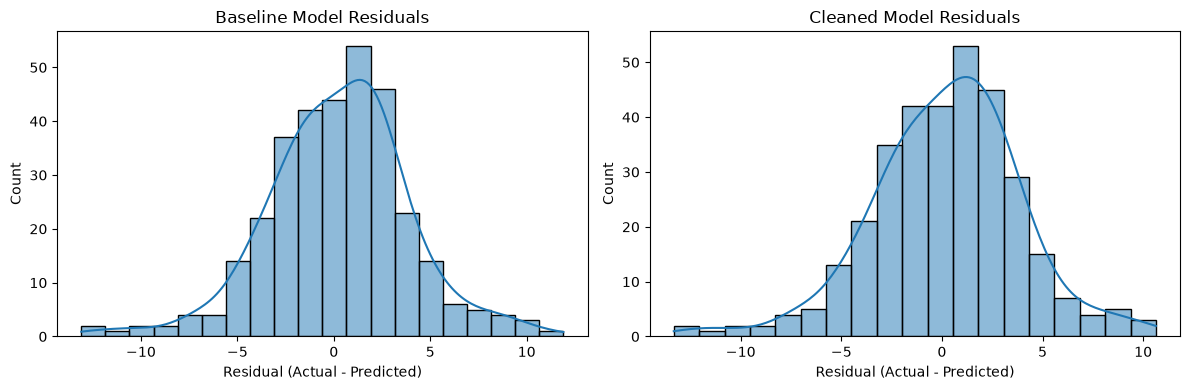

In [15]:
#defining residual calculation for both models
baseline_residuals = y_test - y_predicted
clean_residuals = y_test - clean_predicted

#visualizing two plots for side to side comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

#plotting baseline model residuals with a density curve
sns.histplot(baseline_residuals, kde=True, ax=axes[0])
axes[0].set_title("Baseline Model Residuals")
axes[0].set_xlabel("Residual (Actual - Predicted)")

#plotting the cleaned model residuals with a density curve
sns.histplot(clean_residuals, kde=True, ax=axes[1])
axes[1].set_title("Cleaned Model Residuals")
axes[1].set_xlabel("Residual (Actual - Predicted)")

#displaying both histograms
plt.tight_layout()
plt.show()



### Task 4 Results:

Both models produced residual distributions that were **bell-shaped** and centered near zero. However, the distributions were not fully symmetrical, and some extreme residual values were present in both models.

Removing predictors with high VIF values did not change the overall shape of the residual distributions. Both models show similar patterns of prediction errors.


## Task 5: ADD INTERACTION BETWEEN TWO SURVIVING PREDICTORS

In [16]:
#choosing two features that stayed after vif
if "BMI" in X_vif_train.columns and "HIV/AIDS" in X_vif_train.columns:
    feature1 = "BMI"
    feature2 = "HIV/AIDS"
    reason = "The relationship between HIV/AIDS and life expectancy may depend on nutritional health (BMI)."
elif "Alcohol" in X_vif_train.columns and "GDP" in X_vif_train.columns:
    feature1 = "Alcohol"
    feature2 = "GDP"
    reason = "The relationship between alcohol consumption and life expectancy may depend on national wealth (GDP)."
else:
    feature1 = X_vif_train.columns[0]
    feature2 = X_vif_train.columns[1]
    reason = "Explain why you think these two surviving predictors may interact."

print("Selected predictors:", feature1, "and", feature2)
print("Hypothesis:", reason)

X_interaction_train = X_vif_train.copy()
X_interaction_test = X_vif_test.copy()

#multiplying the two scaled predictors to create an interaction term
X_interaction_train["Interaction"] = X_interaction_train[feature1] * X_interaction_train[feature2]
X_interaction_test["Interaction"] = X_interaction_test[feature1] * X_interaction_test[feature2]

interaction_model = LinearRegression()
interaction_model.fit(X_interaction_train, y_train)
interaction_predicted = interaction_model.predict(X_interaction_test)
interaction_r2 = r2_score(y_test, interaction_predicted)

interaction_importance = pd.DataFrame({
    "Feature": X_interaction_train.columns,
    "Coefficient": interaction_model.coef_
})
interaction_coefficient = interaction_importance.loc[
    interaction_importance["Feature"] == "Interaction", "Coefficient"
].iloc[0]

print(f"Cleaned model R-squared:     {clean_r2:.4f}")
print(f"Interaction model R-squared: {interaction_r2:.4f}")
print(f"Interaction coefficient:     {interaction_coefficient:.4f}")
print("Improved test R-squared?", interaction_r2 > clean_r2)

Selected predictors: BMI and HIV/AIDS
Hypothesis: The relationship between HIV/AIDS and life expectancy may depend on nutritional health (BMI).
Cleaned model R-squared:     0.8058
Interaction model R-squared: 0.8075
Interaction coefficient:     0.8624
Improved test R-squared? True


### Task 5 Results: 

I chose BMI and HIV/AIDS to compare as two of the surviving predictos. I think the relationship between BMI and life expectancy could depend on HIV/AIDS. For example, the effects associated with BMI might be different in populations with more aids/hiv spread.

After creating an interaction term and training the new regression model, I got an R-squared score of **0.8075**, compared to **0.8058** for the cleaned model.

The interaction coefficient was **positive (0.8624)**, which indicates that the relationship between BMI and predicted life expectancy becomes more positive as HIV/AIDS values increase, when the other predictors are held constant.

Adding the interaction term slightly improved the model's performance,the increase in R-squared was **0.0017**.
